# Étape 4 : amélioration de l'approche de classification

## Approche de modélisation
**Contexte métier :** un faux négatif (départ non détecté) coûte plus cher qu'un faux positif (geste de rétention inutile). On cherche donc à améliorer le **recall de la classe 1** en gardant une **precision** acceptable.

**Métriques :** recall, precision, F1 de la classe 1, matrice de confusion, courbe précision-rappel. Pas d'accuracy ni d'AUC ROC seuls (trompeuses avec 16 % de partis).

**Découpage :** train / test stratifié (80 / 20), puis validation croisée stratifiée (5 plis) sur le train. Moyenne et écart-type des scores sur les plis.

**Pistes d'amélioration, dans l'ordre :**
1. Pondération des classes (`class_weight`)
2. Choix du seuil de décision (courbe précision-rappel)
3. Feature engineering
4. Si besoin : sur / sous-échantillonnage (`imblearn`)

---
## 1. Chargement et séparation
Même séparation qu'à l'étape 3 : 80 % train / 20 % test, stratifiée (`stratify=y`, `random_state=42`). Les fonctions viennent de `preparation.py`.

In [59]:
from preparation import charger_donnees, preparer_donnees, ajouter_features
from sklearn.model_selection import train_test_split

X, y = preparer_donnees(charger_donnees())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

---
## 2. Validation croisée stratifiée
Le jeu de test ne contient que 47 partis : un seul découpage donne des scores peu fiables. On découpe donc le train en **5 plis stratifiés** : le modèle est entraîné 5 fois, et on observe la **moyenne** (niveau du modèle) et l'**écart-type** (stabilité) des scores.

Référence : Random Forest sans réglage.

In [60]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf = RandomForestClassifier(random_state=42)

scores = cross_validate(
    rf, X_train, y_train,
    cv=cv,
    scoring=["recall", "precision"],
    return_train_score=True
)

print("Recall test  :", scores["test_recall"].mean(), "±", scores["test_recall"].std())
print("Recall train :", scores["train_recall"].mean())

Recall test  : 0.21578947368421053 ± 0.0713929471907923
Recall train : 1.0


**Conclusion :** recall en test = **0,22 ± 0,07** contre 1,00 en train : fort overfitting. Les 0,11 obtenus à l'étape 3 sur un seul découpage étaient dans le bas de cette fourchette.

---
## 3. Pondération des classes (`class_weight="balanced"`)
Avec 16 % de partis, le modèle tend à négliger la classe minoritaire. `class_weight="balanced"` pèse chaque erreur sur un parti environ 5 fois plus qu'une erreur sur un resté.

La fonction `evaluer_modele` encapsule l'évaluation en validation croisée (recall, precision, F1 en test et en train) pour comparer facilement les modèles.

In [61]:
def evaluer_modele(modele, X, y, cv):
    scores = cross_validate(
        modele, X, y,
        cv=cv,
        scoring=["recall", "precision", "f1"],
        return_train_score=True
    )
    for metrique in ["recall", "precision", "f1"]:
        test = scores[f"test_{metrique}"]
        train = scores[f"train_{metrique}"]
        print(f"{metrique:10s} test : {test.mean():.2f} ± {test.std():.2f} | train : {train.mean():.2f}")

rf_balanced = RandomForestClassifier(class_weight="balanced", random_state=42)
evaluer_modele(rf_balanced, X_train, y_train, cv)

recall     test : 0.38 ± 0.09 | train : 1.00
precision  test : 0.63 ± 0.11 | train : 1.00
f1         test : 0.47 ± 0.10 | train : 1.00


**Conclusion :** recall en test **0,22 → 0,38**, precision 0,63. Gain net (supérieur à l'écart-type), mais l'overfitting reste total (train = 1,00).

---
## 4. Limiter la profondeur des arbres (`max_depth=5`)
Des arbres moins profonds ne peuvent plus mémoriser chaque employé : on réduit l'overfitting.

In [62]:
rf_depth = RandomForestClassifier(
    class_weight="balanced",
    max_depth=5,
    random_state=42
)
evaluer_modele(rf_depth, X_train, y_train, cv)

recall     test : 0.54 ± 0.09 | train : 0.86
precision  test : 0.47 ± 0.06 | train : 0.67
f1         test : 0.50 ± 0.06 | train : 0.75


**Conclusion :**

| Random Forest `balanced` | Recall (test) | Precision (test) | F1 (test) | Recall (train) |
|---|---|---|---|---|
| Arbres profonds | 0,38 | 0,63 | 0,47 | 1,00 |
| `max_depth=5` | **0,54** | 0,47 | **0,50** | 0,86 |

L'overfitting diminue nettement et le recall progresse (≈ 25 partis retrouvés sur 47 au lieu de 18), au prix de plus de fausses alertes. Ce compromis est favorable : un départ non détecté coûte plus cher qu'un geste de rétention inutile.

---
## 5. Choix du seuil de décision
Par défaut, un employé est annoncé « parti » si sa probabilité dépasse **0,5**. Ce seuil n'a rien d'obligatoire. On calcule d'abord les probabilités de chaque employé du train **en validation croisée** (`cross_val_predict`) : chaque employé est prédit par un modèle qui ne l'a jamais vu.

In [63]:
from sklearn.model_selection import cross_val_predict

rf_depth = RandomForestClassifier(class_weight="balanced", max_depth=5, random_state=42)

proba = cross_val_predict(
    rf_depth, X_train, y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

print(proba[:10])

[0.2297777  0.47561723 0.3193101  0.60158597 0.35565511 0.61801435
 0.43723065 0.30971081 0.2718457  0.524891  ]


### Courbe précision-rappel
Pour chaque seuil possible : plus le seuil monte, plus la precision monte et plus le recall baisse (et inversement).

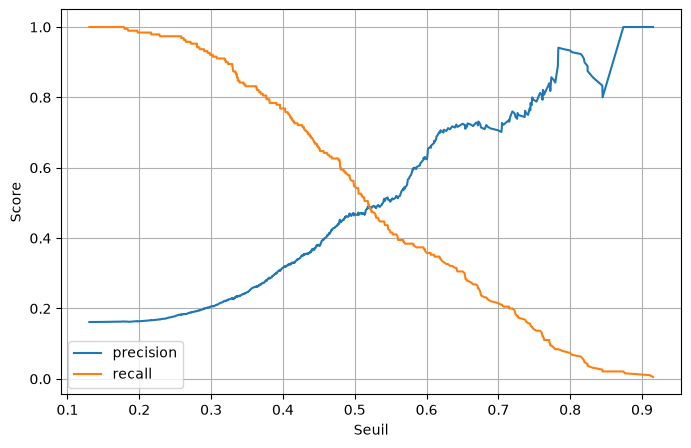

In [64]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precisions, recalls, seuils = precision_recall_curve(y_train, proba)

plt.figure(figsize=(8, 5))
plt.plot(seuils, precisions[:-1], label="precision")
plt.plot(seuils, recalls[:-1], label="recall")
plt.xlabel("Seuil")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

### Scores pour quelques seuils

In [65]:
from sklearn.metrics import recall_score, precision_score, f1_score

for seuil in [0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5]:
    pred = (proba >= seuil).astype(int)
    print(f"seuil {seuil:.2f} | recall {recall_score(y_train, pred):.2f} | "
          f"precision {precision_score(y_train, pred):.2f} | f1 {f1_score(y_train, pred):.2f}")

seuil 0.20 | recall 0.98 | precision 0.16 | f1 0.28
seuil 0.25 | recall 0.97 | precision 0.18 | f1 0.30
seuil 0.30 | recall 0.92 | precision 0.21 | f1 0.34
seuil 0.35 | recall 0.83 | precision 0.25 | f1 0.38
seuil 0.40 | recall 0.77 | precision 0.32 | f1 0.45
seuil 0.45 | recall 0.66 | precision 0.38 | f1 0.48
seuil 0.50 | recall 0.54 | precision 0.47 | f1 0.50


**Choix du seuil : 0,40** (recall 0,77, precision 0,32 en validation croisée).

*Justification métier :* un faux négatif (départ non détecté : recrutement, formation, perte de savoir-faire) coûte plus cher qu'un faux positif (entretien ou geste de rétention). On accepte environ 2 fausses alertes par départ évité. En dessous de 0,40, le gain en recall devient faible par rapport à l'explosion des fausses alertes (le F1 chute).

---
## 6. Évaluation finale sur le jeu de test
Le seuil est fixé **avant** de regarder le test, qui n'est utilisé qu'une fois, pour confirmer.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

SEUIL = 0.40

rf_final = RandomForestClassifier(class_weight="balanced", max_depth=5, random_state=42)
rf_final.fit(X_train, y_train)

proba_test = rf_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= SEUIL).astype(int)

print(classification_report(y_test, pred_test, zero_division=0))
print(confusion_matrix(y_test, pred_test))

              precision    recall  f1-score   support

           0       0.95      0.64      0.77       247
           1       0.30      0.83      0.45        47

    accuracy                           0.67       294
   macro avg       0.63      0.73      0.61       294
weighted avg       0.85      0.67      0.71       294

[[158  89]
 [  8  39]]


**Conclusion :**

| | prédit « resté » | prédit « parti » |
|---|---|---|
| **vrai resté** (247) | 158 | 89 (fausses alertes) |
| **vrai parti** (47) | 8 (partis ratés) | 39 (partis retrouvés) |

- **Recall = 0,83** : 39 des 47 partis sont retrouvés (contre 16 avec la régression logistique de l'étape 3).
- **Precision = 0,30** : ≈ 2,3 fausses alertes par départ évité.
- Résultats proches de la validation croisée (0,77 / 0,32) : le modèle généralise bien.
- L'accuracy (0,67) est inférieure à celle du Dummy (0,84) : sans importance ici, puisque le Dummy ne détecte aucun départ.

---
## 7. Feature engineering
Trois colonnes créées à partir de l'intuition métier (fonction `ajouter_features` dans `preparation.py`) :
- `revenu_par_experience` : revenu mensuel rapporté à l'expérience (sous-paiement relatif) ;
- `stagnation` : années depuis la dernière promotion rapportées à l'ancienneté ;
- `satisfaction_moyenne` : moyenne des 4 scores de satisfaction.

In [67]:
X_train_fe = ajouter_features(X_train)
X_test_fe = ajouter_features(X_test)

rf_fe = RandomForestClassifier(class_weight="balanced", max_depth=5, random_state=42)
evaluer_modele(rf_fe, X_train_fe, y_train, cv)

recall     test : 0.53 ± 0.06 | train : 0.86
precision  test : 0.47 ± 0.04 | train : 0.68
f1         test : 0.50 ± 0.04 | train : 0.76


**Conclusion :** aucune amélioration mesurable (recall 0,53, precision 0,47, F1 0,50, identiques à la référence aux écarts-types près).

In [68]:
import pandas as pd

rf_fe.fit(X_train_fe, y_train)

importances = pd.Series(rf_fe.feature_importances_, index=X_train_fe.columns)
print(importances.sort_values(ascending=False).head(10))

revenu_mensuel                    0.105289
heure_supplementaires             0.101178
annees_dans_l_entreprise          0.099920
annee_experience_totale           0.084542
age                               0.074650
satisfaction_moyenne              0.070769
nombre_participation_pee          0.065737
revenu_par_experience             0.048385
nombre_experiences_precedentes    0.030467
distance_domicile_travail         0.026038
dtype: float64


---
## 8. Sur-échantillonnage (SMOTE)
SMOTE fabrique des partis synthétiques, proches de vrais partis, pour rééquilibrer l'entraînement. Il est appliqué **uniquement sur les données d'entraînement de chaque pli** grâce à un `Pipeline` d'`imblearn` (jamais sur le pli de validation, ce qui fausserait les scores). Pas de `class_weight` ici : SMOTE rééquilibre déjà les classes.

In [69]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

pipe_smote = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("rf", RandomForestClassifier(max_depth=5, random_state=42)),
])

evaluer_modele(pipe_smote, X_train, y_train, cv)

recall     test : 0.47 ± 0.11 | train : 0.65
precision  test : 0.49 ± 0.08 | train : 0.63
f1         test : 0.48 ± 0.08 | train : 0.64


**Conclusion :** pas de gain par rapport à `class_weight="balanced"` (recall 0,47 ± 0,11 contre 0,54 ± 0,09, écart dans le bruit). L'écart train / test est plus faible, mais parce que le modèle apprend moins bien le train, pas parce qu'il généralise mieux. On conserve `class_weight="balanced"`, plus simple.

**Conclusion :** les variables les plus utilisées sont `revenu_mensuel`, `heure_supplementaires` et `annees_dans_l_entreprise`, ce qui confirme l'exploration. Deux nouvelles colonnes sont utilisées (`satisfaction_moyenne` 6e, `revenu_par_experience` 8e), mais elles combinent des informations déjà présentes : un modèle à base d'arbres sait déjà les combiner, d'où l'absence de gain.

---
## 9. Synthèse de l'étape 4
| Modèle | Évaluation | Recall (classe 1) | Precision (classe 1) |
|---|---|---|---|
| Dummy | test | 0,00 | 0,00 |
| Régression logistique (étape 3) | test | 0,34 | 0,62 |
| Random Forest sans réglage | validation croisée | 0,22 | non mesurée |
| + `class_weight="balanced"` | validation croisée | 0,38 | 0,63 |
| + `max_depth=5` | validation croisée | 0,54 | 0,47 |
| + seuil 0,40 | **test** | **0,83** | 0,30 |
| *Essai : SMOTE (sans `class_weight`)* | validation croisée | 0,47 | 0,49 |

- Les gains viennent de la **pondération des classes**, de la **limitation de la profondeur** et surtout du **choix du seuil**, guidé par le contexte métier.
- Le feature engineering simple n'apporte pas de gain, et le sur-échantillonnage (SMOTE) non plus : `class_weight="balanced"` suffit.
- Le modèle final détecte 39 départs sur 47, au prix de 89 fausses alertes sur 247 restés.